<sub>**The Annotated ML Handbook**</sub>

# Solutions: Parts I–IV

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Mahir-606/annotated-ml-handbook/blob/main/solutions/solutions-parts-1-4.ipynb)

Worked solutions to every *Try it yourself* exercise. Try each exercise on your own first. There is usually more than one correct answer; if yours gives the same result, it is right.

In [1]:
# Repository setup (not part of the book's examples): run this cell first.
import os, sys
from pathlib import Path

# Files the examples create (CSV, models, figures) go into ./outputs next to the notebook.
OUT = Path.cwd() if Path.cwd().name == "outputs" else Path.cwd() / "outputs"
OUT.mkdir(exist_ok=True)
os.chdir(OUT)

# insurance.csv is the practice dataset created in Chapter 11 and reused by later chapters.
# If it is not here yet, copy it from the repository's data/ folder (or download it in Colab).
if not Path("insurance.csv").exists():
    import shutil, urllib.request
    for base in OUT.parents:
        if (base / "data" / "insurance.csv").exists():
            shutil.copy(base / "data" / "insurance.csv", "insurance.csv")
            break
    else:
        try:
            urllib.request.urlretrieve("https://raw.githubusercontent.com/Mahir-606/"
                                       "annotated-ml-handbook/main/data/insurance.csv", "insurance.csv")
        except Exception as e:
            print("Could not fetch insurance.csv; run Chapter 11 first.", e)

# The figure style used in the book.
import matplotlib.pyplot as plt
from cycler import cycler
plt.rcParams.update({
    "figure.figsize": (7.2, 4.0), "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.28, "grid.linewidth": 0.6,
    "axes.prop_cycle": cycler(color=["#1f4fff", "#e0245e", "#0f9b62", "#ff6a00",
                                     "#7b3ff2", "#0091b3", "#d99a00", "#d42a2a"]),
    "axes.titleweight": "bold", "axes.titlesize": 12.5, "axes.titlelocation": "left",
    "font.size": 10.5, "legend.frameon": False, "image.cmap": "viridis",
})

# Plotly: interactive in Jupyter/Colab; tools/run_all.py stores static PNGs so GitHub can show them.
try:
    import plotly.io as pio
    pio.renderers.default = os.environ.get("PLOTLY_RENDERER") or (
        "colab" if "google.colab" in sys.modules else "notebook_connected")
except ImportError:
    pass

## Chapter 1: Values, variables and types

**Exercise 1: area of a circle**

In [2]:
import math
r = 2.5
area = math.pi * r ** 2
print(f"area = {area:.3f}")

area = 19.635


**Exercise 2: normalise an e-mail address**

In [3]:
email = "  Ada.Lovelace@Example.COM "
print(email.strip().lower())

ada.lovelace@example.com


**Exercise 3: predict, then check**

In [4]:
print(7 // -2)
print(bool("False"))
print("3" * 3)

-4
True
333


## Chapter 2: Data structures

**Exercise 1: unique lowercase words**

In [5]:
words = ["Data", "science", "IS", "fun", "data"]
print({w.lower() for w in words})

{'science', 'data', 'fun', 'is'}


**Exercise 2: fizz dictionary**

In [6]:
fizz = {n: "fizz" if n % 3 == 0 else n for n in range(1, 11)}
print(fizz)

{1: 1, 2: 2, 3: 'fizz', 4: 4, 5: 5, 6: 'fizz', 7: 7, 8: 8, 9: 'fizz', 10: 10}


**Exercise 3: a mutable list inside an immutable tuple**

In [7]:
t = ([1, 2], 3)
t[0].append(9)
print(t)

([1, 2, 9], 3)


## Chapter 3: Control flow

**Exercise 1: FizzBuzz**

In [8]:
out = []
for n in range(1, 31):
    if n % 15 == 0:
        out.append("FizzBuzz")
    elif n % 3 == 0:
        out.append("Fizz")
    elif n % 5 == 0:
        out.append("Buzz")
    else:
        out.append(str(n))
print(" ".join(out))

1 2 Fizz 4 Buzz Fizz 7 8 Fizz Buzz 11 Fizz 13 14 FizzBuzz 16 17 Fizz 19 Buzz Fizz 22 23 Fizz Buzz 26 Fizz 28 29 FizzBuzz


**Exercise 2: dot product with zip**

In [9]:
a, b = [1, 2, 3], [4, 5, 6]
total = 0
for x, y in zip(a, b):
    total += x * y
print(total)

32


**Exercise 3: halving until below 0.01**

In [10]:
lr, halvings = 1.0, 0
while lr >= 0.01:
    lr /= 2
    halvings += 1
print(halvings, lr)

7 0.0078125


## Chapter 4: Functions

**Exercise 1: describe()**

In [11]:
def describe(values):
    """Return basic summary statistics of a list of numbers."""
    return {"n": len(values), "mean": sum(values) / len(values),
            "min": min(values), "max": max(values)}

print(describe([4, 8, 15, 16, 23, 42]))

{'n': 6, 'mean': 18.0, 'min': 4, 'max': 42}


**Exercise 2: a call-counting decorator**

In [12]:
from functools import wraps

def count_calls(func):
    count = 0
    @wraps(func)
    def wrapper(*args, **kwargs):
        nonlocal count
        count += 1
        print(f"{func.__name__} called {count} time(s)")
        return func(*args, **kwargs)
    return wrapper

@count_calls
def greet(name):
    return f"hi {name}"

greet("Ada"); greet("Alan")

greet called 1 time(s)
greet called 2 time(s)


'hi Alan'

**Exercise 3: running mean generator**

In [13]:
def running_mean(xs):
    total = 0
    for i, x in enumerate(xs, start=1):
        total += x
        yield total / i

print(list(running_mean([2, 4, 6, 8])))

[2.0, 3.0, 4.0, 5.0]


## Chapter 5: Classes and objects

**Exercise 1: a Counter class**

In [14]:
class Counter:
    def __init__(self):
        self.counts = {}
    def add(self, item):
        self.counts[item] = self.counts.get(item, 0) + 1
        return self
    def most_common(self):
        return max(self.counts, key=self.counts.get)

c = Counter().add("a").add("b").add("a")
print(c.most_common(), c.counts)

a {'a': 2, 'b': 1}


**Exercise 2: __len__ for Dataset**

In [15]:
class Dataset:
    def __init__(self, name, values):
        self.name, self.values = name, list(values)
    def __len__(self):
        return len(self.values)

ds = Dataset("heights", [1.6, 1.7, 1.8])
print(len(ds))

3


**Exercise 3: MedianRegressor**

In [16]:
import statistics

class Model:
    def fit(self, X, y):
        self.fitted = True
        return self

class MedianRegressor(Model):
    def fit(self, X, y):
        self.median_ = statistics.median(y)
        return super().fit(X, y)
    def predict(self, X):
        return [self.median_] * len(X)

m = MedianRegressor().fit([[0]] * 5, [1, 2, 3, 100, 4])
print(m.predict([[0], [0]]), m.fitted)

[3, 3] True


## Chapter 6: Errors, files and modules

**Exercise 1: read_numbers() skipping bad lines**

In [17]:
from pathlib import Path
Path("nums.txt").write_text("1.5\n2\nn/a\n\n3.25\n")

def read_numbers(path):
    numbers = []
    with open(path, encoding="utf-8") as f:
        for line in f:
            try:
                numbers.append(float(line))
            except ValueError:
                continue
    return numbers

print(read_numbers("nums.txt"))

[1.5, 2.0, 3.25]


**Exercise 2: save and load a config**

In [18]:
import json
cfg = {"lr": 0.001, "epochs": 50, "layers": [64, 32]}
Path("config.json").write_text(json.dumps(cfg, indent=2))
loaded = json.loads(Path("config.json").read_text())
print(loaded == cfg, loaded["layers"])

True [64, 32]


**Exercise 3: count CSV files recursively**

In [19]:
for sub in ["tree/a", "tree/b/c"]:
    Path(sub).mkdir(parents=True, exist_ok=True)
for f in ["tree/x.csv", "tree/a/y.csv", "tree/b/c/z.csv", "tree/b/notes.txt"]:
    Path(f).write_text("")
print(len(list(Path("tree").glob("**/*.csv"))))

3


## Chapter 7: The Pythonic toolkit

**Exercise 1: the most common words**

In [20]:
from collections import Counter
text = "the model learns the data and the data teaches the model"
print(Counter(text.lower().split()).most_common(3))

[('the', 4), ('model', 2), ('data', 2)]


**Exercise 2: all 12 combinations**

In [21]:
from itertools import product
combos = list(product([0.1, 1, 10], ["linear", "rbf", "poly", "sigmoid"]))
print(len(combos), combos[:4])

12 [(0.1, 'linear'), (0.1, 'rbf'), (0.1, 'poly'), (0.1, 'sigmoid')]


**Exercise 3: extract e-mail addresses**

In [22]:
import re
s = "Contact ada@lab.org or alan.t@uni.ac.uk; not me@ or @bad.com"
print(re.findall(r"[\w.+-]+@[\w-]+(?:\.[\w-]+)+", s))

['ada@lab.org', 'alan.t@uni.ac.uk']


## Chapter 8: NumPy arrays

**Exercise 1: the centre 3x3 block**

In [23]:
import numpy as np
A = np.arange(1, 26).reshape(5, 5)
print(A[1:4, 1:4])

[[ 7  8  9]
 [12 13 14]
 [17 18 19]]


**Exercise 2: fraction beyond 2 standard deviations**

In [24]:
x = np.random.default_rng(0).normal(size=1000)
z = (x - x.mean()) / x.std()
print((np.abs(z) > 2).mean())

0.042


**Exercise 3: sums along each axis of a 3-D array**

In [25]:
B = np.arange(24).reshape(2, 3, 4)
for ax in range(3):
    print(ax, B.sum(axis=ax).shape)

0 (3, 4)
1 (2, 4)
2 (2, 3)


## Chapter 9: Computing with NumPy

**Exercise 1: min-max scaling with broadcasting**

In [26]:
rng = np.random.default_rng(1)
M = rng.normal(5, 3, (100, 4))
scaled = (M - M.min(axis=0)) / (M.max(axis=0) - M.min(axis=0))
print(scaled.min(axis=0), scaled.max(axis=0))

[0. 0. 0. 0.] [1. 1. 1. 1.]


**Exercise 2: class proportions**

In [27]:
labels = rng.choice([0, 1], 500, p=[.8, .2])
vals, counts = np.unique(labels, return_counts=True)
print(dict(zip(vals.tolist(), (counts / counts.sum()).round(3).tolist())))

{0: 0.768, 1: 0.232}


**Exercise 3: a linear system**

In [28]:
A = np.array([[3, 2], [1, -1]])
b = np.array([7, -1])
print(np.linalg.solve(A, b))

[1. 2.]


## Chapter 10: Machine learning from scratch

**Exercise 1: L2-regularised gradient descent**

In [29]:
rng = np.random.default_rng(7)
X = rng.uniform(0, 10, (200, 1))
y = 2.5 * X[:, 0] - 4 + rng.normal(0, 2, 200)
Xb = np.column_stack([np.ones(200), X])

def gd_ridge(alpha, lr=0.02, epochs=3000):
    w = np.zeros(2)
    for _ in range(epochs):
        grad = 2 / len(y) * Xb.T @ (Xb @ w - y)
        grad[1:] += 2 * alpha * w[1:]
        w -= lr * grad
    return w

for alpha in [0, 0.1, 1, 10]:
    print(alpha, gd_ridge(alpha).round(3))

0 [-4.132  2.502]
0.1 [-3.986  2.473]
1 [-2.81   2.239]
10 [2.664 1.15 ]


**Exercise 2: overlapping classes**

In [30]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

for centre in [1.5, 0.5]:
    Xc = np.vstack([rng.normal(-centre, 1, (150, 2)), rng.normal(centre, 1, (150, 2))])
    yc = np.r_[np.zeros(150), np.ones(150)]
    Xcb = np.column_stack([np.ones(300), Xc])
    w = np.zeros(3)
    for _ in range(1000):
        w -= 0.5 * Xcb.T @ (sigmoid(Xcb @ w) - yc) / 300
    print(f"centres ±{centre}: accuracy = {np.mean((sigmoid(Xcb @ w) >= 0.5) == yc):.3f}")

centres ±1.5: accuracy = 0.980


centres ±0.5: accuracy = 0.750


**Exercise 3: multiclass kNN with bincount**

In [31]:
def knn_predict(X_train, y_train, X_new, k=5):
    d = np.sqrt(((X_new[:, None, :] - X_train[None, :, :]) ** 2).sum(-1))
    nearest = np.argsort(d, axis=1)[:, :k]
    votes = y_train[nearest]
    return np.array([np.bincount(row).argmax() for row in votes])

from sklearn.datasets import load_iris
Xi, yi = load_iris(return_X_y=True)
perm = rng.permutation(150)
tr, te = perm[:120], perm[120:]
print("accuracy:", np.mean(knn_predict(Xi[tr], yi[tr], Xi[te], k=5) == yi[te]))

accuracy: 0.9333333333333333


## Chapter 11: pandas foundations

**Exercises 1-3**

In [32]:
import pandas as pd
df = pd.read_csv("insurance.csv")
q1 = df[(df["sex"] == "female") & (df["smoker"] == "yes") & (df["region"] == "southeast") & (df["age"] > 40)]
print("Exercise 1:", len(q1))
df["bmi_class"] = pd.cut(df["bmi"], bins=[0, 18.5, 25, 30, np.inf],
                         labels=["under", "normal", "over", "obese"], right=False)
print("Exercise 2:", df["bmi_class"].value_counts().to_dict())
q3 = df[df["children"] == 4].nsmallest(5, "age").sort_values("charges")
print("Exercise 3:\n", q3[["age", "children", "charges"]])

Exercise 1: 8
Exercise 2: {'obese': 452, 'over': 290, 'normal': 191, 'under': 27}
Exercise 3:
      age  children   charges
79    33         4  14660.57
508   28         4  16158.67
919   22         4  17032.08
299   30         4  20662.30
227   24         4  38993.78


## Chapter 12: Cleaning data

**Exercise 1: group-wise median imputation**

In [33]:
df = pd.read_csv("insurance.csv")
print("missing before:", df["bmi"].isna().sum())
df["bmi"] = df["bmi"].fillna(df.groupby(["sex", "smoker"])["bmi"].transform("median"))
print("missing after:", df["bmi"].isna().sum())

missing before: 40
missing after: 0


**Exercise 2: IQR outliers in charges**

In [34]:
q1, q3 = df["charges"].quantile([0.25, 0.75])
iqr = q3 - q1
out = df[(df["charges"] < q1 - 1.5 * iqr) | (df["charges"] > q3 + 1.5 * iqr)]
print(len(out), "outliers;", out["smoker"].value_counts().to_dict())

145 outliers; {'yes': 145}


**Exercise 3: a validation function**

In [35]:
def check_insurance(d):
    bad_age = d[~d["age"].between(18, 64)]
    if len(bad_age):
        raise ValueError(f"{len(bad_age)} ages outside 18-64, e.g. {bad_age['age'].head(3).tolist()}")
    if (d["charges"] < 0).any():
        raise ValueError("negative charges found")
    return True

print(check_insurance(df))
try:
    check_insurance(pd.DataFrame({"age": [30, 70], "charges": [100, 200]}))
except ValueError as e:
    print("caught:", e)

True
caught: 1 ages outside 18-64, e.g. [70]


## Chapter 13: Grouping, reshaping, joining

**Exercise 1: smoking share and median charges by region**

In [36]:
smoke_share = df.groupby("region")["smoker"].apply(lambda s: (s == "yes").mean()).rename("smoker_share")
med = df.pivot_table(values="charges", index="region", columns="smoker", aggfunc="median")
med.columns = ["median_nonsmoker", "median_smoker"]
print(pd.concat([smoke_share, med], axis=1).round(2))

           smoker_share  median_nonsmoker  median_smoker
region                                                  
northeast          0.17          17418.84       40210.35
northwest          0.16          16689.04       39713.74
southeast          0.20          17189.18       41128.19
southwest          0.21          17277.98       41133.62


**Exercise 2: melt, then group**

In [37]:
long = df.melt(value_vars=["age", "bmi", "charges"], var_name="variable", value_name="value")
print(long.groupby("variable")["value"].mean().round(2))

variable
age           40.71
bmi           29.52
charges    21473.52
Name: value, dtype: float64


**Exercise 3: weekly resampling**

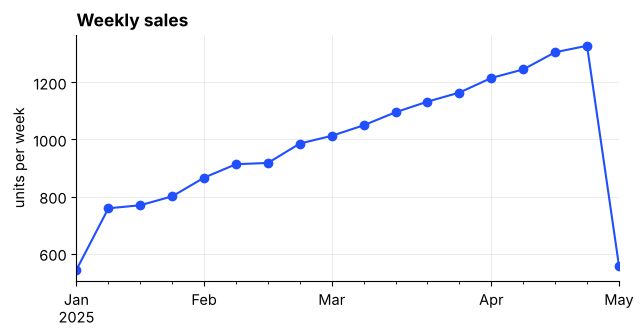

In [38]:
import matplotlib.pyplot as plt
rng = np.random.default_rng(1)
dates = pd.date_range("2025-01-01", periods=120, freq="D")
sales = pd.Series(100 + np.arange(120) * 0.8 + rng.normal(0, 8, 120) + 15 * np.sin(np.arange(120) / 7 * 2 * np.pi), index=dates)
weekly = sales.resample("W").sum()
ax = weekly.plot(marker="o", figsize=(7, 3.2), title="Weekly sales")
ax.set_ylabel("units per week")
plt.show()

## Chapter 14: Matplotlib and Seaborn basics

**Exercise 1: charges vs log(charges)**

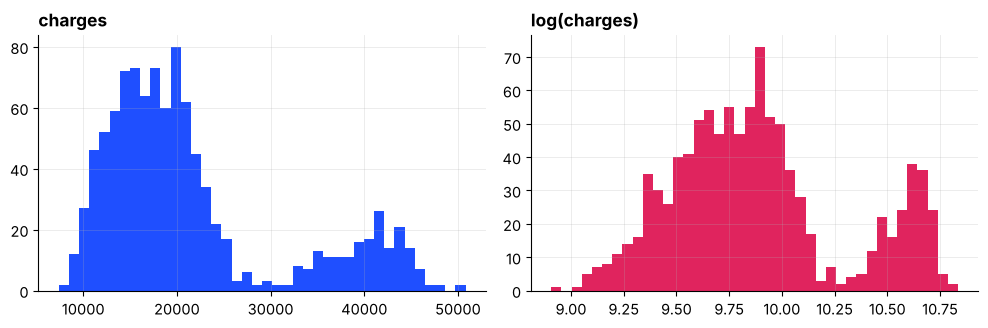

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].hist(df["charges"], bins=40); axes[0].set_title("charges")
axes[1].hist(np.log(df["charges"]), bins=40, color="#e0245e"); axes[1].set_title("log(charges)")
plt.tight_layout(); plt.show()

**Exercises 2 and 3: region pair plot and bars with CIs**

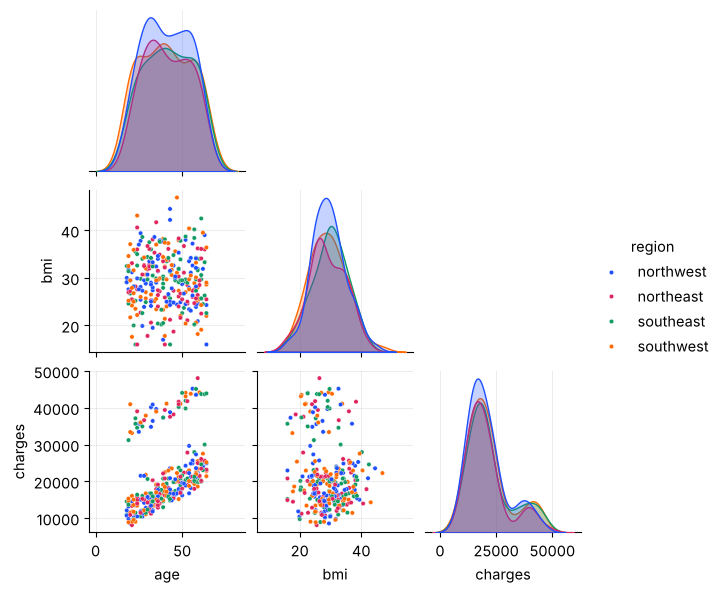

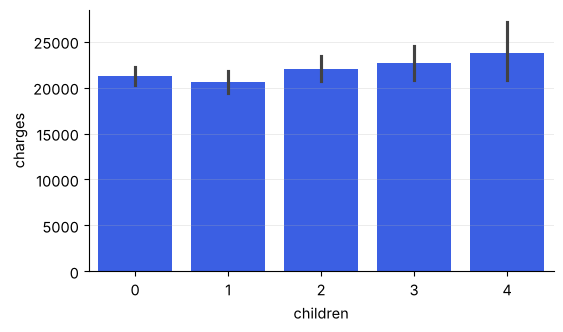

In [40]:
import seaborn as sns
g = sns.pairplot(df.sample(300, random_state=0), vars=["age", "bmi", "charges"], hue="region", corner=True, height=2, plot_kws={"s": 10})
plt.show()
fig, ax = plt.subplots(figsize=(6, 3.4))
sns.barplot(data=df, x="children", y="charges", ax=ax)
plt.show()

## Chapter 15: The Matplotlib gallery

**Exercise 1: grouped bars of mean charges**

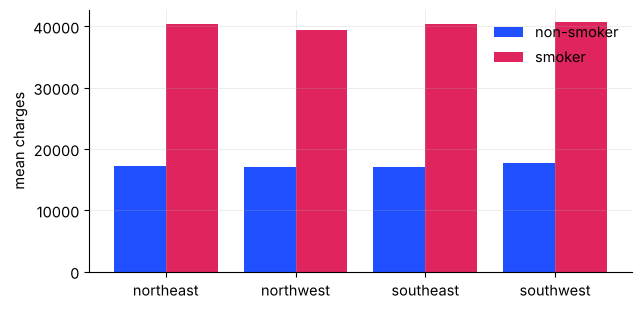

In [41]:
m = df.pivot_table(values="charges", index="region", columns="smoker", aggfunc="mean")
x = np.arange(len(m)); w = 0.4
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.bar(x - w / 2, m["no"], w, label="non-smoker")
ax.bar(x + w / 2, m["yes"], w, label="smoker")
ax.set(xticks=x, xticklabels=m.index, ylabel="mean charges")
ax.legend(); plt.show()

**Exercise 2: ECDF of BMI by sex**

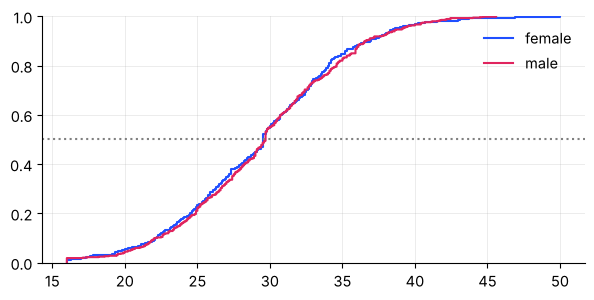

sex
female    29.5
male      29.7
Name: bmi, dtype: float64


In [42]:
fig, ax = plt.subplots(figsize=(7, 3.2))
for sex in ["female", "male"]:
    ax.ecdf(df.loc[df["sex"] == sex, "bmi"].dropna(), label=sex)
ax.axhline(0.5, ls=":", color="grey"); ax.legend(); plt.show()
print(df.groupby("sex")["bmi"].median())

**Exercise 3: 600-dpi PNG vs PDF**

In [43]:
from pathlib import Path
fig, ax = plt.subplots(figsize=(3.5, 2.6))
ax.plot(range(10), np.arange(10) ** 2, marker="o")
fig.savefig("ex600.png", dpi=600); fig.savefig("ex600.pdf"); plt.close(fig)
print({f: Path(f).stat().st_size // 1024 for f in ["ex600.png", "ex600.pdf"]})

{'ex600.png': 76, 'ex600.pdf': 4}


## Chapter 16: The Seaborn gallery

**Exercise 1: violins by children and smoker**

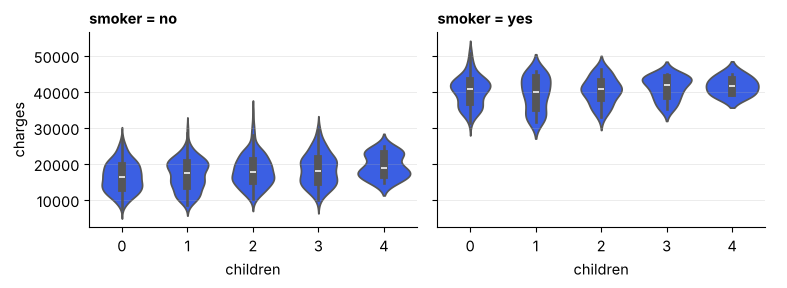

In [44]:
g = sns.catplot(data=df, x="children", y="charges", col="smoker", kind="violin", height=3, aspect=1.3)
plt.show()

**Exercise 2: jointplot with a regression line**

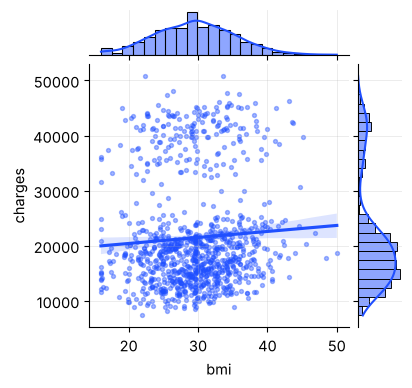

In [45]:
g = sns.jointplot(data=df, x="bmi", y="charges", kind="reg", height=4, scatter_kws={"s": 8, "alpha": 0.4})
plt.show()

**Exercise 3: clustermap with smokers marked**

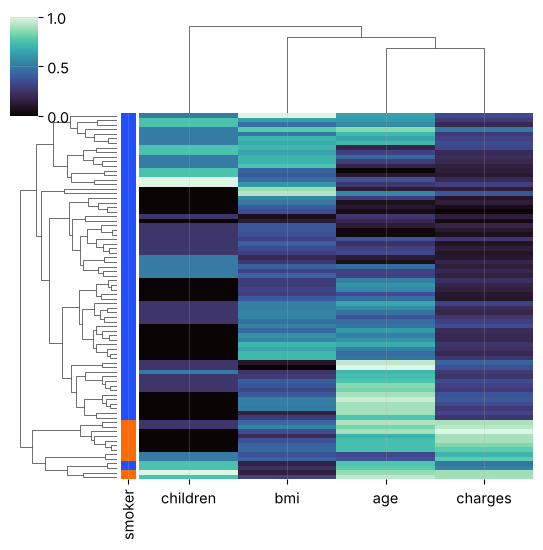

In [46]:
sub = df.dropna().sample(80, random_state=0)
num = sub[["age", "bmi", "children", "charges"]]
g = sns.clustermap(num, standard_scale=1, row_colors=sub["smoker"].map({"yes": "#ff6a00", "no": "#1f4fff"}),
                   cmap="mako", figsize=(5.5, 5.5), yticklabels=False)
plt.show()

## Chapter 17: Interactive charts with Plotly

**Exercises 1 and 2: animated bars and a three-level sunburst**

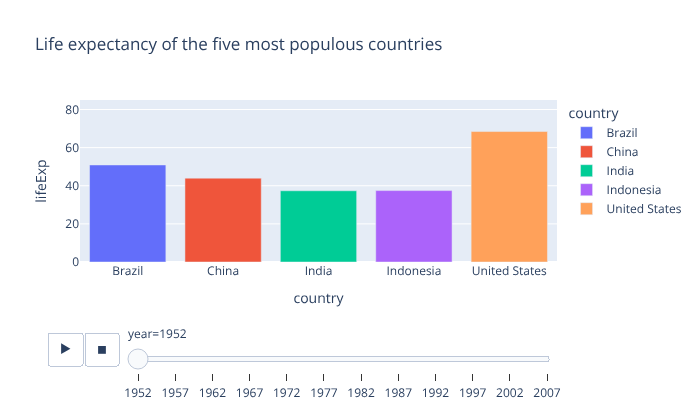

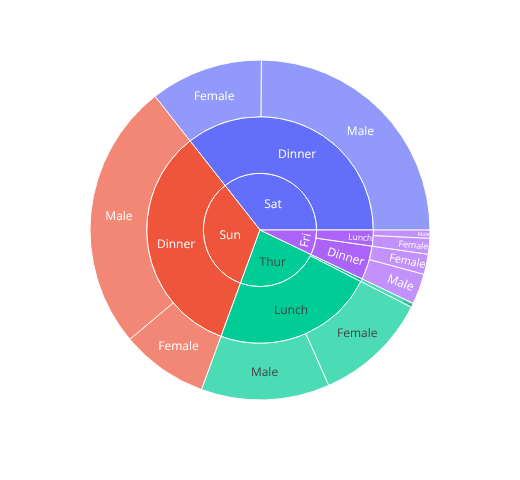

In [47]:
import plotly.express as px
gap = px.data.gapminder()
top5 = gap[gap["year"] == 2007].nlargest(5, "pop")["country"]
fig = px.bar(gap[gap["country"].isin(top5)], x="country", y="lifeExp", color="country",
             animation_frame="year", range_y=[0, 85], width=700, height=420,
             title="Life expectancy of the five most populous countries")
fig.show()
fig2 = px.sunburst(px.data.tips(), path=["day", "time", "sex"], values="tip", width=520, height=480)
fig2.show()

**Exercise 3: a 7-inch, 300-dpi-equivalent PNG**

In [48]:
fig2.write_image("sunburst.png", width=700, height=600, scale=3)
from PIL import Image
with Image.open("sunburst.png") as im:
    print(im.size, "->", im.size[0] / 300, "inches wide at 300 dpi")

(2100, 1800) -> 7.0 inches wide at 300 dpi


## Chapter 18: Figures for papers

**Exercises 1-3: final-size export and checking pixels**

In [49]:
plt.rcParams.update({"font.size": 8})

def save_figure(fig, name, folder="figures", formats=("pdf", "png"), dpi=300):
    out = Path(folder); out.mkdir(parents=True, exist_ok=True)
    paths = [out / f"{name}.{f}" for f in formats]
    for p in paths:
        fig.savefig(p, dpi=dpi, bbox_inches="tight")
    return paths

fig, axes = plt.subplots(1, 3, figsize=(7, 3), layout="constrained")
axes[0].hist(df["age"], bins=20); axes[0].set_xlabel("Age (years)")
axes[1].scatter(df["age"], df["charges"] / 1000, s=3, c=(df["smoker"] == "yes"), cmap="coolwarm")
axes[1].set_xlabel("Age (years)"); axes[1].set_ylabel("Charges (k$)")
df.groupby("smoker")["charges"].median().div(1000).plot.bar(ax=axes[2], color=["#1f4fff", "#ff6a00"])
axes[2].set_ylabel("Median charges (k$)")
for ax, letter in zip(axes, "abc"):
    ax.text(-0.25, 1.02, letter, transform=ax.transAxes, fontweight="bold", fontsize=10)
paths = save_figure(fig, "three_panel")
plt.close(fig)
with Image.open(paths[1]) as im:
    print(im.size, "pixels ≈", round(im.size[0] / 300, 2), "x", round(im.size[1] / 300, 2), "inches at 300 dpi")
plt.rcdefaults()

(2134, 934) pixels ≈ 7.11 x 3.11 inches at 300 dpi
